In [1]:
from sklearn.datasets import load_iris
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [5]:
iris = load_iris()
x = iris.data
feature_names = iris.feature_names
y = iris.target
df = pd.DataFrame(x, columns=feature_names)
display(df)
df["target"] = y
display(df)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [3]:
result = []

for i in range(1, 3):
    lda = LinearDiscriminantAnalysis(n_components=i)

    x_lda = lda.fit_transform(x, y)

    print("\nn_components =", i)
    print("Variance ratio =", lda.explained_variance_ratio_)
    print("Sum ratio =", sum(lda.explained_variance_ratio_))

    result.append(x_lda)


n_components = 1
Variance ratio = [0.9912126]
Sum ratio = 0.9912126049653671

n_components = 2
Variance ratio = [0.9912126 0.0087874]
Sum ratio = 0.9999999999999999


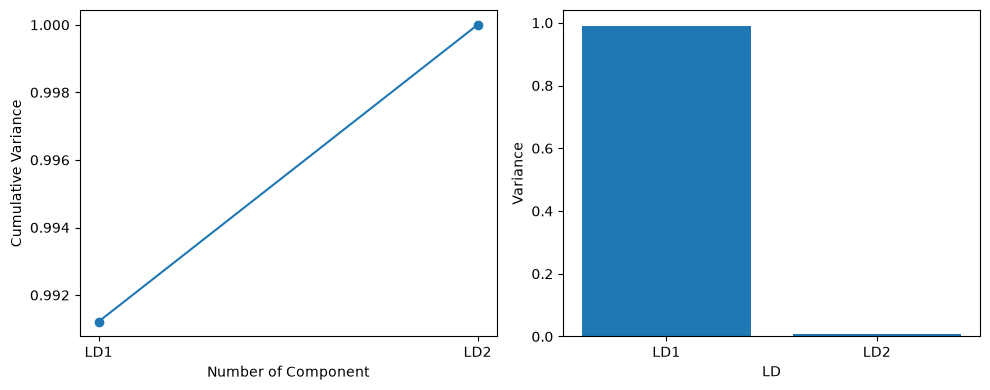

In [4]:
lda = LinearDiscriminantAnalysis(n_components=2)
x_lda = lda.fit_transform(x, y)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# Cumulative variance
axs[0].plot(
    np.cumsum(lda.explained_variance_ratio_),
    marker="o"
)

axs[0].set_xlabel("Number of Component")
axs[0].set_ylabel("Cumulative Variance")
axs[0].set_xticks([0, 1], ["LD1", "LD2"])

# Her component'in variance oranı
axs[1].bar(
    ["LD1", "LD2"],
    lda.explained_variance_ratio_
)

axs[1].set_xlabel("LD")
axs[1].set_ylabel("Variance")

plt.tight_layout()
plt.show()